<a href="https://colab.research.google.com/github/Shivankar7/Shivankar-Sinha/blob/main/Shivankar_sinha_23BDS0026_EDA_Fertility_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
#Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
plt.style.use("ggplot")
print("Libraries Imported Successfully")

Libraries Imported Successfully


In [29]:
# Load Dataset

from google.colab import files
uploaded = files.upload()
df = pd.read_csv("Fertility2.csv")

Saving Fertility2.csv to Fertility2 (2).csv


In [30]:
#Display Dataset
print("First Five Rows")
display(df.head())
print("\nLast Five Rows")
display(df.tail())

First Five Rows


,rownames,morekids,gender1,gender2,age,afam,hispanic,other,work
0,1,no,female,female,35,no,no,no,40
1,2,no,female,male,33,no,no,no,52
2,3,no,female,female,28,no,no,no,12
3,4,no,male,male,28,no,no,no,0
4,5,no,female,male,31,no,no,no,0



Last Five Rows


,rownames,morekids,gender1,gender2,age,afam,hispanic,other,work
29995,29996,yes,male,female,34,no,no,no,0
29996,29997,no,male,male,30,no,no,no,4
29997,29998,yes,male,female,34,no,no,no,42
29998,29999,yes,male,male,31,yes,no,no,52
29999,30000,no,female,female,29,no,no,no,0


In [31]:
#Dataset Information
print("Shape of Dataset:", df.shape)
print("\nColumn Names")
print(df.columns)
print("\nData Types")
print(df.dtypes)
print("\nInformation")
df.info()

Shape of Dataset: (30000, 9)

Column Names
Index(['rownames', 'morekids', 'gender1', 'gender2', 'age', 'afam', 'hispanic',
       'other', 'work'],
      dtype='object')

Data Types
rownames     int64
morekids    object
gender1     object
gender2     object
age          int64
afam        object
hispanic    object
other       object
work         int64
dtype: object

Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   rownames  30000 non-null  int64 
 1   morekids  30000 non-null  object
 2   gender1   30000 non-null  object
 3   gender2   30000 non-null  object
 4   age       30000 non-null  int64 
 5   afam      30000 non-null  object
 6   hispanic  30000 non-null  object
 7   other     30000 non-null  object
 8   work      30000 non-null  int64 
dtypes: int64(3), object(6)
memory usage: 2.1+ MB


In [32]:
#Statistical Analysis
print("Statistical Summary")
display(df.describe())

Statistical Summary


,rownames,age,work
count,30000.000000,30000.000000,30000.000000
mean,15000.500000,30.354267,19.209500
std,8660.398374,3.383432,21.941018
min,1.000000,21.000000,0.000000
25%,7500.750000,28.000000,0.000000
50%,15000.500000,31.000000,6.000000
75%,22500.250000,33.000000,45.000000
max,30000.000000,35.000000,52.000000


rownames    0
morekids    0
gender1     0
gender2     0
age         0
afam        0
hispanic    0
other       0
work        0
dtype: int64
rownames    0.0
morekids    0.0
gender1     0.0
gender2     0.0
age         0.0
afam        0.0
hispanic    0.0
other       0.0
work        0.0
dtype: float64


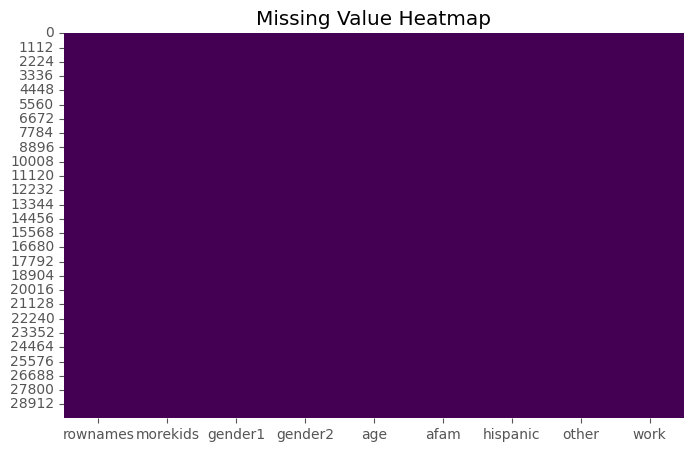

In [33]:
#Missing data analysis
print(df.isnull().sum())
missing = (df.isnull().sum()/len(df))*100
print(missing)
plt.figure(figsize=(8,5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Value Heatmap")
plt.show()

In [34]:
#Handle Missing Values
numeric_columns=df.select_dtypes(include=np.number).columns

df[numeric_columns]=df[numeric_columns].fillna(df[numeric_columns].mean())
categorical_columns=df.select_dtypes(include='object').columns

for col in categorical_columns:
    df[col]=df[col].fillna(df[col].mode()[0])

In [35]:
#Data cleaning
print("Duplicate Rows =",df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Duplicates Removed")
df.columns=df.columns.str.strip()
df.columns

Duplicate Rows = 0
Duplicates Removed


Index(['rownames', 'morekids', 'gender1', 'gender2', 'age', 'afam', 'hispanic',
       'other', 'work'],
      dtype='object')

In [36]:
#Data transformation

#1.Label Encoding
encoder=LabelEncoder()

for col in categorical_columns:
    df[col]=encoder.fit_transform(df[col])

print("Categorical Data Encoded Successfully")

#2.Feature Scaling
scaler=StandardScaler()

df[numeric_columns]=scaler.fit_transform(df[numeric_columns])

print("Numerical Features Standardized")

Categorical Data Encoded Successfully
Numerical Features Standardized


Histogram


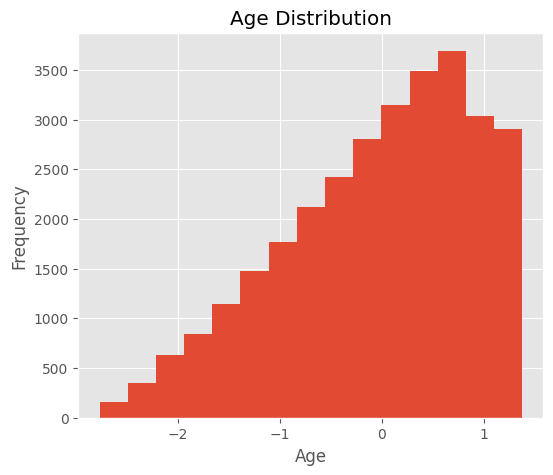

Boxplot


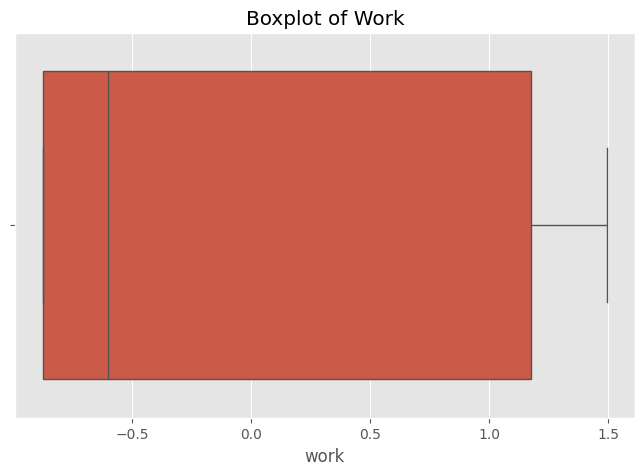

Count Plot


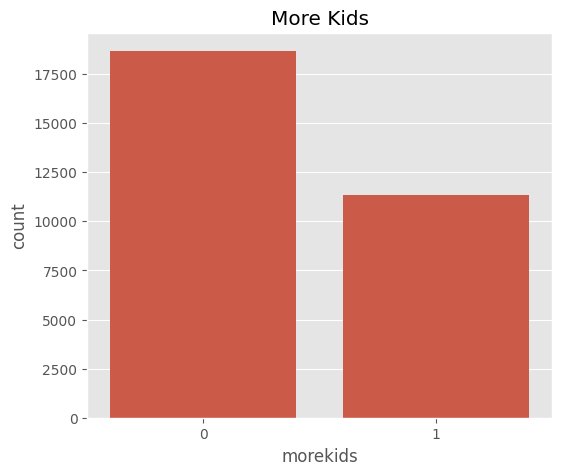

In [37]:
#Univariate analysis with a minimum of three visualizations

#1.Histogram (Age)
print("Histogram")
plt.figure(figsize=(6,5))
plt.hist(df["age"],bins=15)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

#2.Boxplot
print("Boxplot")
plt.figure(figsize=(8,5))
sns.boxplot(x=df["work"])
plt.title("Boxplot of Work")
plt.show()

#3.Count Plot
print("Count Plot")
plt.figure(figsize=(6,5))
sns.countplot(x="morekids",data=df)
plt.title("More Kids")
plt.show()

Scatter Plot


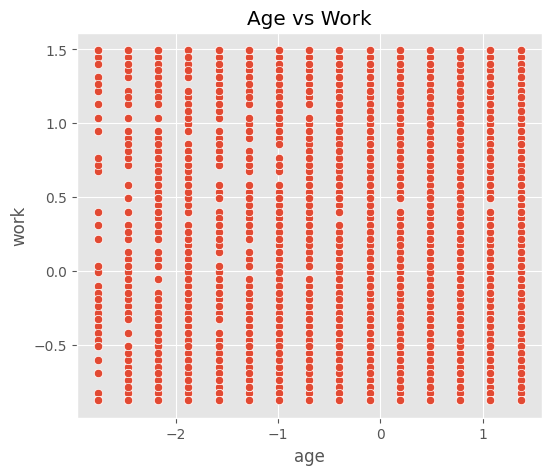

Boxplot


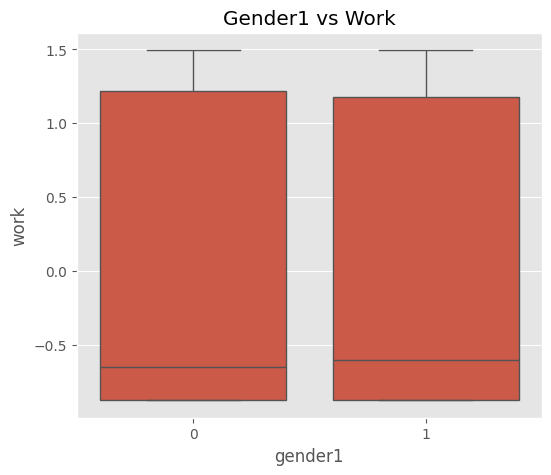

Heatmap


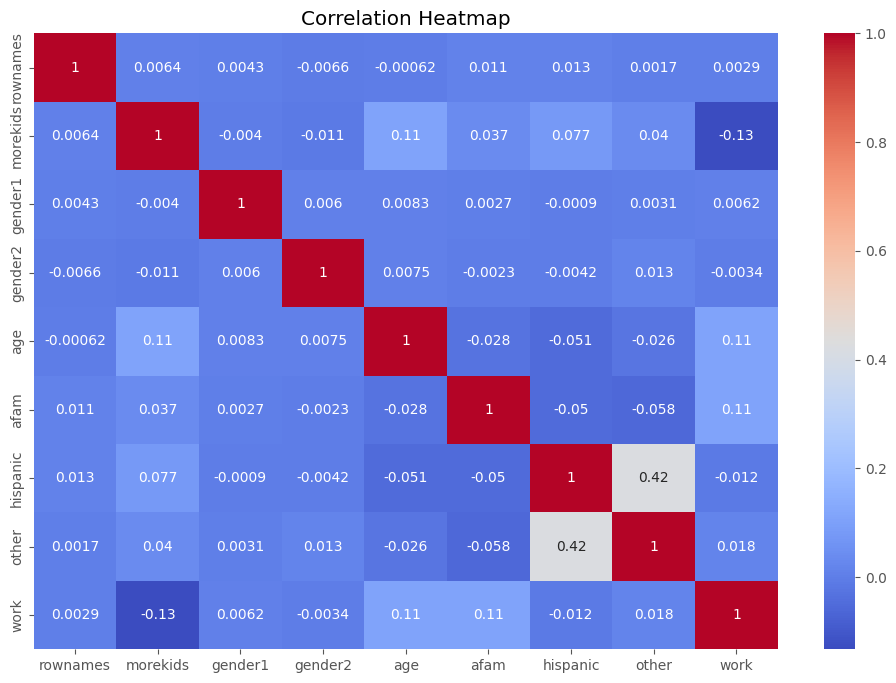

In [38]:
#Bivariate analysis with a minimum of three visualizations

#1.Scatter Plot(Age vs Work)
print("Scatter Plot")
plt.figure(figsize=(6,5))
sns.scatterplot(x="age",y="work",data=df)
plt.title("Age vs Work")
plt.show()

#2.Boxplot(Gender1 vs Work)
print("Boxplot")
plt.figure(figsize=(6,5))
sns.boxplot(x="gender1",y="work",data=df)
plt.title("Gender1 vs Work")
plt.show()

#3.Correlation Heatmap
print("Heatmap")
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

Pair plot


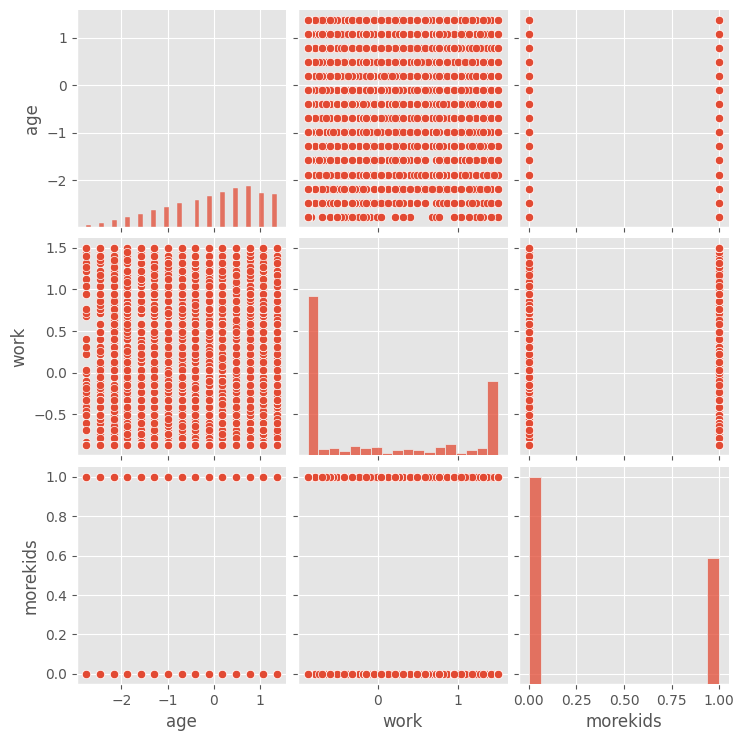

Heatmap


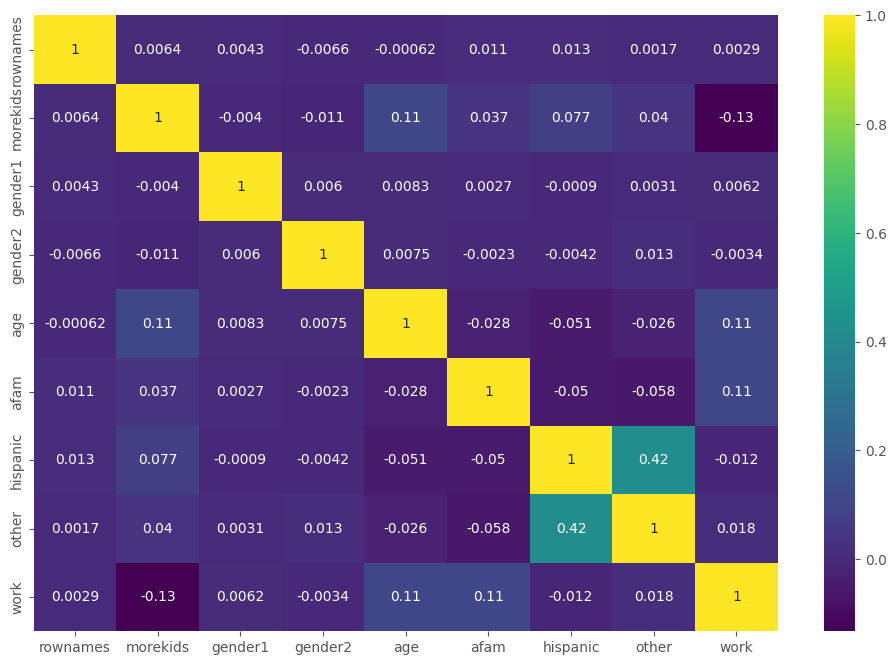

Scatter Plot


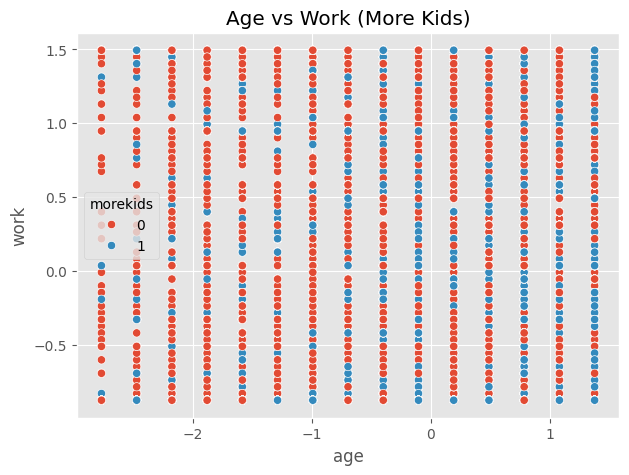

In [39]:
#Multivariate analysis with a minimum of three visualizations

#1.Pair Plot
print("Pair plot")
sns.pairplot(df[["age","work","morekids"]])
plt.show()

#2.Heatmap
print("Heatmap")
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot=True,cmap="viridis")
plt.show()

#3.Scatter Plot
print("Scatter Plot")
plt.figure(figsize=(7,5))
sns.scatterplot(x="age",y="work",hue="morekids",data=df)
plt.title("Age vs Work (More Kids)")
plt.show()

In [40]:
#Final Dataset
df.head()

,rownames,morekids,gender1,gender2,age,afam,hispanic,other,work
0,-1.731993,0,0,0,1.373106,0,0,0,0.947579
1,-1.731878,0,0,1,0.781980,0,0,0,1.494509
2,-1.731762,0,0,0,-0.695834,0,0,0,-0.328591
3,-1.731647,0,1,1,-0.695834,0,0,0,-0.875521
4,-1.731531,0,0,1,0.190855,0,0,0,-0.875521
